<a href="https://colab.research.google.com/github/Minimire/CROP-RECOMMENDATION-app/blob/main/Module_6_pythons.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#CELL 1-install dependencies & load  dataset
print("\n"+"#"*50+"\n")
!pip install -q xgboost shap optuna openpyxl joblib
import os,warnings,joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
SEEDS=[0,42,123]
RANDOM_STATE=SEEDS
np.random.seed(RANDOM_STATE)
print("\n3-tier dataset loader")
print("\n"+"#"*50+"\n")
DATA_XLSX="Crop_recommendation.xlsx"
DATA_CSV="Crop_recommendation.csv"
# Fixed case-sensitivity: 'Data_Processed' instead of 'Data_processed'
URL="https://raw.githubusercontent.com/Gladiator07/Harvestify/master/Data-processed/crop_recommendation.csv"
if os.path.exists(DATA_XLSX):
   df=pd.read_excel(DATA_XLSX)
   print(f"LOADED {DATA_XLSX}")
elif os.path.exists(DATA_CSV):
   df=pd.read_csv(DATA_CSV)
   print(f"LOADED {DATA_CSV}")
else:
   df=pd.read_csv(URL)
   print(f"LOADED FROM THE URL THAT IS (SAME KAGGLE DATA)")
print(f"shape:{df.shape}")
print(f"Columns:{list(df.columns)}")
df.head()


##################################################


3-tier dataset loader

##################################################

LOADED FROM THE URL THAT IS (SAME KAGGLE DATA)
shape:(2200, 8)
Columns:['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice



##################################################


CHECKING THE DATASET FOR THE MISSING VALUES,DUPLICATED,MAKING THE CLASS COUNT AND PLOT THE DISTRIBUTION,CORRELATIONS

##################################################


CHECKING ON THE CLEANENESS OF DATASE
MISSING VALUES: 0
Count Duplicate rows: 0
The Classes counts: 22
Samples per class: [100]
Soil pH mean: 6.47
Rainfall mean: 20.2 -> 298.6
TEMPERATURE: 9.0 -> 43.67549305
TEMPERATURE MEAN: 25.6162438518
HUMIDITY: 14.26 -> 99.98187601
HUMIDITY MEAN: 71.4818

##################################################

PLOT THE DISTRIBUTIOM OF THE CLASSES

##################################################



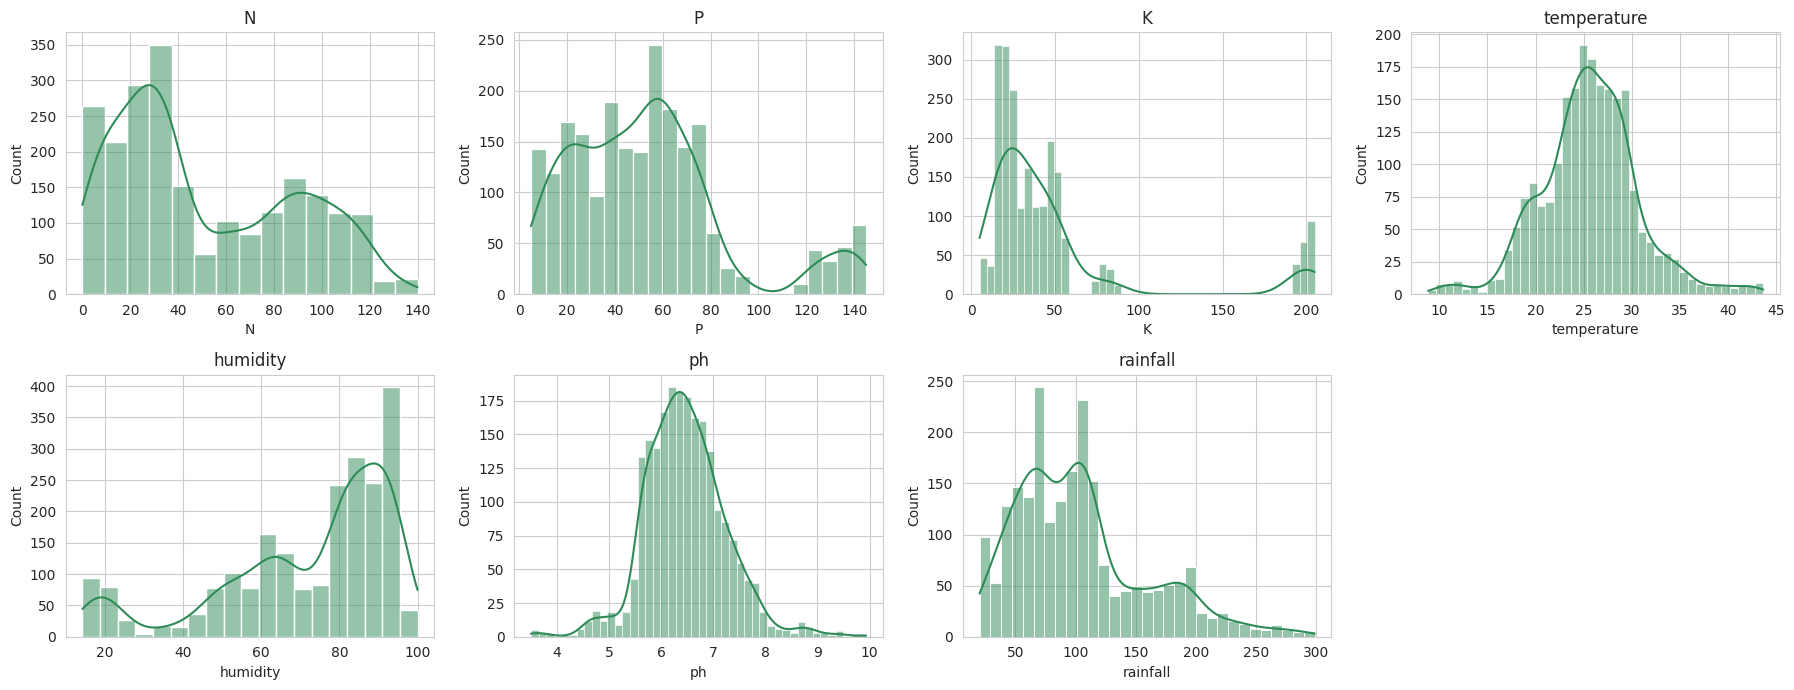


##################################################

PLOT THE CORRELATION BETWEEN THE FEATURES

##################################################



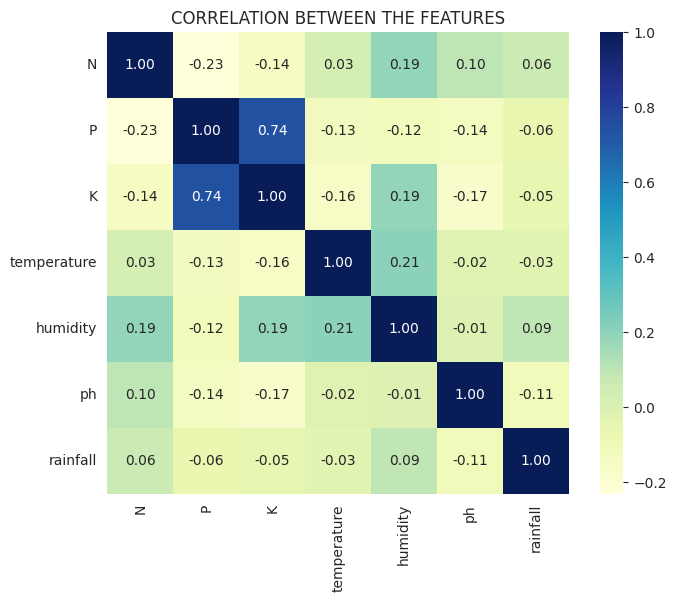


##################################################

PLOT THE RAINFALL FOR EVERY CROP:(RICE THRESHOLD INSIGHT)

##################################################



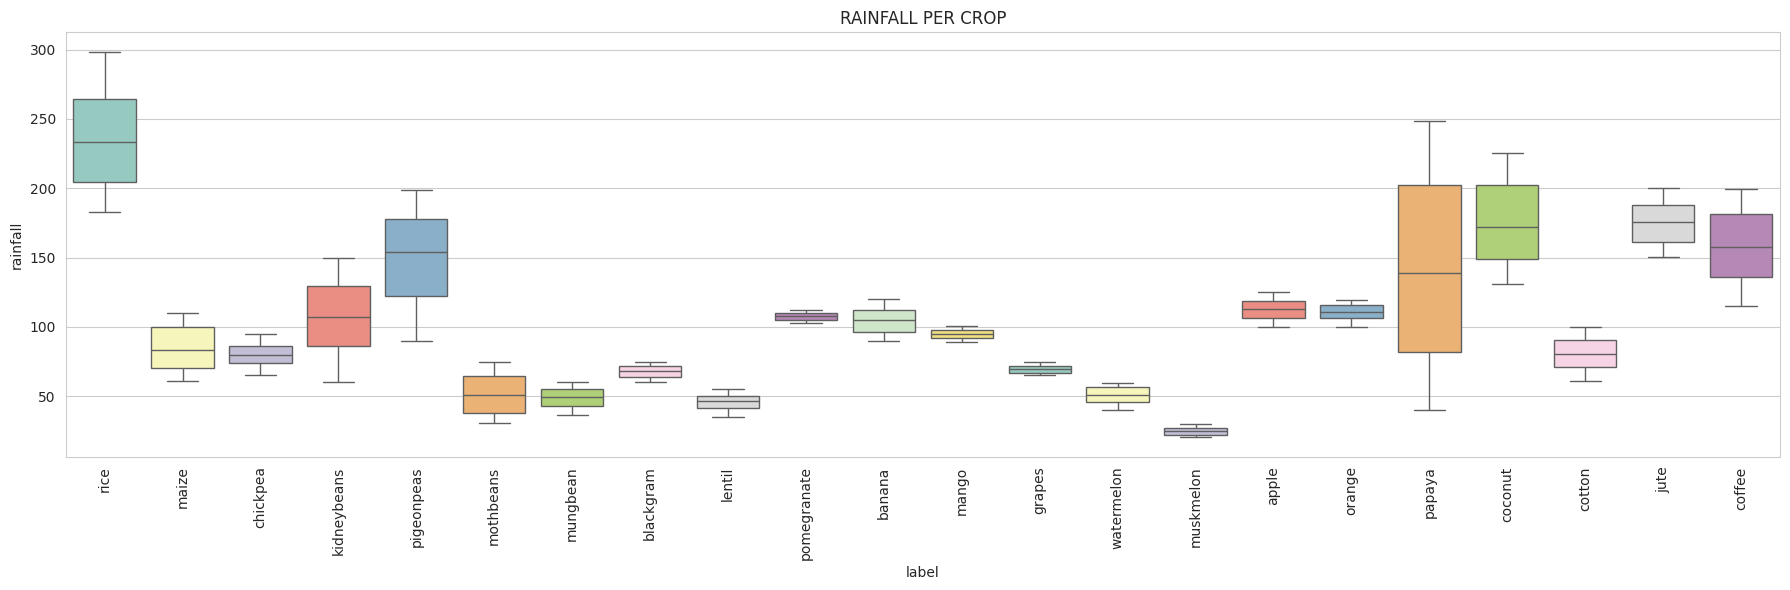


##################################################


TOP-5 HIGH - POTASSIIUM CROPS:

##################################################

label
grapes        200.1
apple         199.9
chickpea       79.9
watermelon     50.2
muskmelon      50.1
Name: K, dtype: float64


In [ ]:
#CELL-2 ON DATASET CHECKS AND CLEANING
print("\n"+"#"*50+"\n")
print("\nCHECKING THE DATASET FOR THE MISSING VALUES,DUPLICATED,MAKING THE CLASS COUNT AND PLOT THE DISTRIBUTION,CORRELATIONS")
print("\n"+"#"*50+"\n")
# Columns in DataFrame are lowercase: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']
FEATURES=["N","P","K","temperature","humidity","ph","rainfall"]
print("\nCHECKING ON THE CLEANENESS OF DATASE")
print("MISSING VALUES:",int(df.isnull().sum().sum()))
print("Count Duplicate rows:",int(df.duplicated().sum()))
print("The Classes counts:",df["label"].nunique())
print("Samples per class:",df["label"].value_counts().unique())
print("Soil pH mean:",round(df["ph"].mean(),2))
print("Rainfall mean:",round(df["rainfall"].min(),1),"->",round(df["rainfall"].max(),1))
print("TEMPERATURE:",round(df["temperature"].min(),0),"->",round(df["temperature"].max(),100))
print("TEMPERATURE MEAN:",round(df["temperature"].mean(),10))
print("HUMIDITY:",round(df["humidity"].min(),2),"->",round(df["humidity"].max(),50))
print("HUMIDITY MEAN:",round(df["humidity"].mean(),4))
print("\n"+"#"*50+"\n")
print("PLOT THE DISTRIBUTIOM OF THE CLASSES")
print("\n"+"#"*50+"\n")
#PLOT THE CLASS DISTRIBUTION
fig,axes=plt.subplots(nrows=2,ncols=4,figsize=(18,7))
axes = axes.flatten() # Fixed: assigned the flattened array back to axes
for i,col in enumerate(FEATURES):
  sns.histplot(df[col],kde=True,ax=axes[i],color="seagreen") # Fixed color name typo
  axes[i].set_title(col)
axes[-1].axis("off")
plt.tight_layout()
plt.show()
print("\n"+"#"*50+"\n")
print("PLOT THE CORRELATION BETWEEN THE FEATURES")
print("\n"+"#"*50+"\n")
#PLOT FOR THE CORRELATION ESTABLISHED AMONG THE FEATURES
plt.figure(figsize=(8,6))
sns.heatmap(df[FEATURES].corr(),annot=True,fmt=".2f",cmap="YlGnBu",square=True)
plt.title("CORRELATION BETWEEN THE FEATURES");
plt.show()
print("\n"+"#"*50+"\n")
print("PLOT THE RAINFALL FOR EVERY CROP:(RICE THRESHOLD INSIGHT)")
print("\n"+"#"*50+"\n")
#THE RAINFALL PLOT AGAINST EVERY CROP
plt.figure(figsize=(18,6)) # Fixed: 'figsiz' to 'figsize'
sns.boxplot(data=df,x="label",y="rainfall",palette="Set3")
plt.xticks(rotation=90);
plt.title("RAINFALL PER CROP");
plt.tight_layout();
plt.show()
print("\n"+"#"*50+"\n")
print("\nTOP-5 HIGH - POTASSIIUM CROPS:")
print("\n"+"#"*50+"\n")
print(df.groupby("label")["K"].mean().sort_values(ascending=False).head(5).round(1))

In [ ]:
#CELL-3: ON DATA PREPOCESSING
print("\n"+"#"*50+"\n")
print("\nDATA PREPROCESSING")
print("\n"+"#"*50+"\n")
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
X=df[FEATURES].copy()
y_raw=df["label"].copy()
label_encoder=LabelEncoder()
y=label_encoder.fit_transform(y_raw)
print("Encoded Classes(22):")
for i,c in enumerate(label_encoder.classes_):
  print(f"{i:2d}->{c}")
  X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
  print("\n"+"#"*50+"\n")
  print(f"\nTRAIN:{X_train.shape}|TEST:{X_test.shape}")
  print("\nSCALER FITING ON THE TRAINING ONLY HENCE AVOID DATA LEAKADE")
  scaler=StandardScaler()
  X_train=scaler.fit_transform(X_train)
  X_test=scaler.transform(X_test)   #THE FITTING ONLY ABOUT THE TRAINING NOT ONTO THE X_TEST
  print("\nSAVE PREPROCESSING ARTIFACTS")
  joblib.dump(scaler,"scaler.joblib")
  joblib.dump({"features":FEATURES,"label_encoder":label_encoder,"scaler":scaler},"preprocessing.pkl")
  print("Saved preprocessing.pkl")


##################################################


DATA PREPROCESSING

##################################################

Encoded Classes(22):
 0->apple

##################################################


TRAIN:(1760, 7)|TEST:(440, 7)

SCALER FITING ON THE TRAINING ONLY HENCE AVOID DATA LEAKADE

SAVE PREPROCESSING ARTIFACTS
Saved preprocessing.pkl
 1->banana

##################################################


TRAIN:(1760, 7)|TEST:(440, 7)

SCALER FITING ON THE TRAINING ONLY HENCE AVOID DATA LEAKADE

SAVE PREPROCESSING ARTIFACTS
Saved preprocessing.pkl
 2->blackgram

##################################################


TRAIN:(1760, 7)|TEST:(440, 7)

SCALER FITING ON THE TRAINING ONLY HENCE AVOID DATA LEAKADE

SAVE PREPROCESSING ARTIFACTS
Saved preprocessing.pkl
 3->chickpea

##################################################


TRAIN:(1760, 7)|TEST:(440, 7)

SCALER FITING ON THE TRAINING ONLY HENCE AVOID DATA LEAKADE

SAVE PREPROCESSING ARTIFACTS
Saved preprocessing.pkl
 4->cocon

In [ ]:
#CELL-4; ON THE SEED-ROBUSTNESS AUDIT FOR RF AND XGB
print("\nSEED-ROBUSTNESS AUDIT FOR THE RANDOM FOREST AND XGBOOST")
print("\n"+"#"*50+"\n")
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score
import numpy as np
SEEDS=[0,42,123]
RANDOM_STATE=SEEDS
rf_accs,xgb_accs=[],[]
for seed in SEEDS:
  Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=0.2,random_state=seed,stratify=y)
rf=RandomForestClassifier(n_estimators=500,random_state=42,n_jobs=-1).fit(Xtr,ytr)
rf_acc=accuracy_score(yte,rf.predict(Xte))
rf_accs.append(rf_acc)
xgb=XGBClassifier(n_estimators=200,learning_rate=0.1,random_state=42,max_depth=5,objective="multi:softprob",num_class=22,n_jobs=-1,eval_metric="mlogloss",tree_methods="hist").fit(Xtr,ytr)
xgb_acc=accuracy_score(yte,xgb.predict(Xte))
xgb_accs.append(xgb_acc)
print(f"seed{seed:3d}|RF={rf_acc:.4f}(+/-{np.std(rf_accs):.4f})|XGB={xgb_acc:.4f}(+/-{np.std(xgb_accs):.4f})")
print(f"seed{seed:3d}|RF={rf_acc:.4f}({rf_acc*100:.2f}%)"f"|XGB={xgb_acc:.4f}({xgb_acc*100:.2f}%)")
print("\n"+"#"*50+"\n")
print(f"RandomForest:{np.mean(rf_accs):.4f}+/-{np.std(rf_accs):.4f}"f"({np.mean(rf_accs)*100:.2f}%+/-{np.std(rf_accs)*100:.2f}%)")
print(f"XGBoost:{np.mean(xgb_accs):.4f}+/-{np.std(xgb_acc):.4f}"f"({np.mean(xgb_accs)*100:.2f}%{np.std(xgb_accs)*100:.2f}%)")
print("\n"+"#"*50+"\n")
print(f"Range(RF):{min(rf_accs)*100:.2f}%->{max(rf_accs)*100:.2f}%")


SEED-ROBUSTNESS AUDIT FOR THE RANDOM FOREST AND XGBOOST

##################################################

seed123|RF=0.9932(+/-0.0000)|XGB=0.9909(+/-0.0000)
seed123|RF=0.9932(99.32%)|XGB=0.9909(99.09%)

##################################################

RandomForest:0.9932+/-0.0000(99.32%+/-0.00%)
XGBoost:0.9909+/-0.0000(99.09%0.00%)

##################################################

Range(RF):99.32%->99.32%


In [ ]:
# CELL-5: ON TRAINIG AND COMPARING ALL MODELS
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Using 42 directly to avoid the list of seeds issue from CELL-4
models={
    "Dummy":DummyClassifier(strategy="most_frequent"),
    "Logistic Regression":Pipeline([("sc",StandardScaler()),("clf",LogisticRegression(max_iter=2000,random_state=42))]),
    "KNN(k=5)":Pipeline([("sc",StandardScaler()),("clf",KNeighborsClassifier(n_neighbors=5))]),
    "Random Forest":RandomForestClassifier(n_estimators=500,random_state=42,n_jobs=-1),
    "XGBoost":XGBClassifier(n_estimators=200,learning_rate=0.1,max_depth=5,objective="multi:softprob",num_class=22,eval_metric="mlogloss",tree_method="hist",random_state=42),
    }
rows,trained=[],{}
for name,m in models.items():
   m.fit(X_train,y_train)
   p=m.predict(X_test)
   trained[name]=m
   rows.append({"Model":name,
               "Accuracy":accuracy_score(y_test,p),
               "Precision":precision_score(y_test,p,average="macro",zero_division=0),
               "Recall":recall_score(y_test,p,average="macro",zero_division=0),
               "F1":f1_score(y_test,p,average="macro",zero_division=0)})
results=pd.DataFrame(rows).sort_values("Accuracy",ascending=False).reset_index(drop=True)
display(results.style.format({"Accuracy":"{:.2%}","Precision":"{:.2%}","Recall":"{:.2%}","F1":"{:.2%}"}))

,Model,Accuracy,Precision,Recall,F1
0,Random Forest,99.55%,99.57%,99.55%,99.55%
1,XGBoost,98.64%,98.74%,98.64%,98.62%
2,KNN(k=5),97.95%,98.04%,97.95%,97.93%
3,Logistic Regression,97.27%,97.40%,97.27%,97.25%
4,Dummy,4.55%,0.21%,4.55%,0.40%


In [ ]:
#CELL-6; ON TUNED THE RANDOM FOREST WITH GRIDSEARCH CV ACROSS MULTIPLE SEEDS
print("\n"+"#"*50+"\n")
print("\nTHE RESULT FOR RANDOM FOREST MODEL TUNED UNDER GRIDSEARCH CV ACROSS SEEDS")
print("\n"+"#"*50+"\n")
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import numpy as np

param_grid={
    "n_estimators":[200,500,800],
    "max_depth":[None,15,25],
    "max_features":["sqrt","log2"],
}

# We will run the GridSearch for each seed in our SEEDS list [0, 42, 123]
seeds_to_test = [0, 42, 123]
all_seed_test_accs = []

for seed in seeds_to_test:
    print(f"--- Running GridSearch for Seed: {seed} ---")
    gs=GridSearchCV(
        RandomForestClassifier(random_state=seed, n_jobs=-1),
        param_grid,cv=5,scoring="accuracy",n_jobs=-1,verbose=0
    )
    gs.fit(X_train, y_train)
    rf_best=gs.best_estimator_
    rf_test_acc=accuracy_score(y_test, rf_best.predict(X_test))
    all_seed_test_accs.append(rf_test_acc)

    print(f"Seed {seed:3d} | Best CV Acc: {gs.best_score_:.4f} | Test Acc: {rf_test_acc:.4f} ({rf_test_acc:.2%})")
    print(f"Best Params: {gs.best_params_}\n")

print("\n"+"#"*50+"\n")
print(f"Overall Multi-Seed RF Test Accuracy: {np.mean(all_seed_test_accs):.4f} (+/- {np.std(all_seed_test_accs):.4f})")
print("\n"+"#"*50+"\n")


##################################################


THE RESULT FOR RANDOM FOREST MODEL TUNED UNDER GRIDSEARCH CV ACROSS SEEDS

##################################################

--- Running GridSearch for Seed: 0 ---
Seed   0 | Best CV Acc: 0.9955 | Test Acc: 0.9932 (99.32%)
Best Params: {'max_depth': None, 'max_features': 'sqrt', 'n_estimators': 200}

--- Running GridSearch for Seed: 42 ---
Seed  42 | Best CV Acc: 0.9949 | Test Acc: 0.9955 (99.55%)
Best Params: {'max_depth': None, 'max_features': 'sqrt', 'n_estimators': 500}

--- Running GridSearch for Seed: 123 ---
Seed 123 | Best CV Acc: 0.9949 | Test Acc: 0.9955 (99.55%)
Best Params: {'max_depth': None, 'max_features': 'sqrt', 'n_estimators': 200}


##################################################

Overall Multi-Seed RF Test Accuracy: 0.9947 (+/- 0.0011)

##################################################



In [ ]:
# Set RANDOM_STATE back to a single integer for notebook consistency
RANDOM_STATE = 42
print(f"RANDOM_STATE has been reset to: {RANDOM_STATE}")